# Resume Screening and Ranking System
Future Interns, Machine Learning Task 3

What this notebook builds, in order:
1. Loads the resume and job description datasets, cleans the text and removes the job title leak
2. Audits the data: fixes the role mapping and excludes a category whose labels are unreliable
3. Builds evaluation queries with a title based tune and test split
4. Defines strict relevance (exact category) and graded relevance (related categories earn partial credit)
5. Extracts skills with spaCy and splits them into required and preferred
6. Scores resumes with TF IDF, BM25, sentence embeddings (two models, whole resume or chunked) and skill coverage
7. Picks the best embedding variant and tunes the hybrid blend on the tuning queries only
8. Reports results on the held out test queries, with bootstrap confidence intervals
9. Explains every ranking in plain language, with a chart

This is a ranking and explanation system, not a classifier. Scores are relative to the resume pool.
The category labels are a proxy for real hiring decisions, and the README should say so.

## 1. Setup

In [22]:
# Run this once if a library is missing. Kaggle already has most of them.
# On Kaggle, internet must be ON so the embedding models can download.
# %pip install -q sentence-transformers spacy scikit-learn matplotlib pandas numpy

In [23]:
import re
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from spacy.matcher import PhraseMatcher
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sentence_transformers import SentenceTransformer

# A fixed seed makes every random choice repeatable.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

In [24]:
# One block decides where we are running. Nothing else in the notebook cares about it.
ON_KAGGLE = Path("/kaggle/input").exists()

if ON_KAGGLE:
    DATA_ROOT = Path("/kaggle/input")
    OUTPUT_DIR = Path("/kaggle/working/outputs")
    FIG_DIR = Path("/kaggle/working/figures")
else:
    # Locally the notebook sits in notebooks/, so the project root is one level up.
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent
    DATA_ROOT = PROJECT_ROOT / "raw_data"
    OUTPUT_DIR = PROJECT_ROOT / "outputs"
    FIG_DIR = PROJECT_ROOT / "docs" / "images"

for folder in (OUTPUT_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def find_file(filename):
    """Search DATA_ROOT and all its subfolders for a file, so folder layout does not matter."""
    matches = list(DATA_ROOT.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"{filename} not found under {DATA_ROOT}. Attach or download it first.")
    return matches[0]


print("Running on Kaggle:", ON_KAGGLE)
print("Data folder:", DATA_ROOT)

Running on Kaggle: True
Data folder: /kaggle/input


## 2. Load the data

In [25]:
resumes = pd.read_csv(find_file("Resume.csv"), usecols=["ID", "Resume_str", "Category"])
resumes["Resume_str"] = resumes["Resume_str"].fillna("")
print(resumes.shape)
print(resumes["Category"].value_counts())

(2484, 3)
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


In [26]:
# The job description file is huge, so we read only the first 100000 rows.
# If this cell raises a column error, check the real names with:
#   pd.read_csv(find_file("job_descriptions.csv"), nrows=0).columns
JD_ROWS_TO_READ = 100000
JD_COLUMNS = ["Job Title", "Role", "Job Description", "skills", "Responsibilities"]

jobs_raw = pd.read_csv(find_file("job_descriptions.csv"), usecols=JD_COLUMNS, nrows=JD_ROWS_TO_READ)
print(jobs_raw.shape)

(100000, 5)


## 3. Text cleaning and the title leak fix
Most resumes start with their job title in CAPITAL LETTERS. That title is basically the
category label, so leaving it in would make every method look better than it is.
We strip the leading capitalised words before doing anything else.

In [27]:
def strip_leading_title(text, max_tokens=15):
    """Remove the run of ALL CAPS words at the start of a resume (the leaked job title)."""
    tokens = str(text).split()
    i = 0
    while i < len(tokens) and i < max_tokens and tokens[i] == tokens[i].upper():
        i += 1
    return " ".join(tokens[i:])


def clean_text(text):
    """Lowercase, drop links and emails, keep letters, digits, + and # (so c++ and c# survive)."""
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z0-9+# ]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


sample_raw = resumes["Resume_str"].iloc[0]
print("BEFORE:", sample_raw[:150].strip())
print("AFTER :", strip_leading_title(sample_raw)[:150])

BEFORE: HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in H
AFTER : Summary Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management. Respected builder and leader o


In [28]:
resumes["resume_body"] = resumes["Resume_str"].apply(strip_leading_title)
resumes["clean"] = resumes["resume_body"].apply(clean_text)

# Drop near empty resumes and exact duplicates, so one resume cannot appear twice in a ranking.
resumes = resumes[resumes["clean"].str.len() > 200]
resumes = resumes.drop_duplicates(subset="clean").reset_index(drop=True)
print("Resumes kept:", len(resumes))

Resumes kept: 2481


### Data audit: is the ADVOCATE label reliable?
In an earlier run, ADVOCATE job queries kept returning AUTOMOBILE and AVIATION resumes,
and a sample of ADVOCATE resumes showed mostly non legal careers.
This check measures the share of resumes in each category that mention any legal word.
The word list is crude, so treat the numbers as a hint, not proof.

In [29]:
legal_pattern = r"\b(?:law|legal|attorney|lawyer|paralegal|litigation|court|counsel)\b"
has_legal = resumes["clean"].str.contains(legal_pattern, regex=True)
print(has_legal.groupby(resumes["Category"]).mean().round(2).sort_values(ascending=False))

# Result we saw: only about 37 percent of ADVOCATE resumes mention a legal word, so about 63
# percent have none. The label is not trustworthy ground truth, so we exclude ADVOCATE from
# the evaluation queries. The ADVOCATE resumes stay in the pool as ordinary distractors.
# We will say this openly in the README, including that we noticed it through poor scores.
EXCLUDED_CATEGORIES = {"ADVOCATE"}

Category
HR                        0.50
ADVOCATE                  0.37
AUTOMOBILE                0.31
BANKING                   0.28
FINANCE                   0.28
PUBLIC-RELATIONS          0.25
HEALTHCARE                0.24
BPO                       0.23
ACCOUNTANT                0.22
CONSULTANT                0.21
AGRICULTURE               0.21
CONSTRUCTION              0.20
INFORMATION-TECHNOLOGY    0.18
BUSINESS-DEVELOPMENT      0.18
FITNESS                   0.17
DIGITAL-MEDIA             0.16
AVIATION                  0.15
ARTS                      0.14
APPAREL                   0.13
TEACHER                   0.12
CHEF                      0.10
SALES                     0.09
ENGINEERING               0.08
DESIGNER                  0.07
Name: clean, dtype: float64


## 4. Map job titles to resume categories
The two datasets share no key. A resume counts as relevant to a job if its category matches
the job's category. Rules are checked in order and the first match wins.
We audited these rules by printing the titles that landed in each category:
the consultant rule was dropped (it mixed unrelated roles), tax moved to ACCOUNTANT,
QA and test automation moved to INFORMATION-TECHNOLOGY, and the health rule was narrowed.

In [30]:
ROLE_RULES = [
    (r"\bhuman resources?\b|\bhr\b|recruit|talent", "HR"),
    (r"public relations|\bpr\b|communications?", "PUBLIC-RELATIONS"),
    (r"business development", "BUSINESS-DEVELOPMENT"),
    (r"digital marketing|social media|\bseo\b|content", "DIGITAL-MEDIA"),
    (r"accountant|accounting|bookkeep|\btax\b", "ACCOUNTANT"),
    (r"\bbank|\bloan\b|teller", "BANKING"),
    (r"financial|finance|auditor", "FINANCE"),
    (r"\bsales\b", "SALES"),
    (r"designer|graphic|\bux\b|\bui\b|illustrator", "DESIGNER"),
    (r"nurse|nursing|medical|physician|pharmac|clinical|therapist|psycholog|social worker|counselor", "HEALTHCARE"),
    (r"teacher|instructor|tutor|professor", "TEACHER"),
    (r"attorney|lawyer|legal|paralegal", "ADVOCATE"),
    (r"software|developer|programmer|\bdata\b|database|network|\bsystems?\b|\bweb\b|devops|cloud|cyber|\bit\b|\bqa\b|quality assurance|test automation", "INFORMATION-TECHNOLOGY"),
    (r"engineer", "ENGINEERING"),
    (r"\bchef\b|\bcook\b", "CHEF"),
]


def map_role(text):
    """Return the first matching resume category for a job title, or None."""
    text = " " + str(text).lower() + " "
    for pattern, category in ROLE_RULES:
        if re.search(pattern, text):
            return category
    return None

In [31]:
jobs = jobs_raw.rename(columns={"Job Title": "title", "Role": "role"}).copy()

# The full job text is description, responsibilities and skills joined together.
jobs["jd_text"] = (
    jobs["Job Description"].fillna("") + ". "
    + jobs["Responsibilities"].fillna("") + ". "
    + jobs["skills"].fillna("")
)
jobs["category"] = (jobs["title"].fillna("") + " " + jobs["role"].fillna("")).apply(map_role)
del jobs_raw

print("Mapped share:", round(jobs["category"].notna().mean(), 3))
jobs = jobs.dropna(subset=["category"]).drop_duplicates(subset="jd_text")
jobs = jobs[jobs["category"].isin(resumes["Category"].unique())]
print(jobs["category"].value_counts())

Mapped share: 0.706
category
INFORMATION-TECHNOLOGY    75
DESIGNER                  36
HEALTHCARE                34
DIGITAL-MEDIA             24
ENGINEERING               20
ADVOCATE                  19
SALES                     15
HR                        10
FINANCE                    9
ACCOUNTANT                 9
TEACHER                    6
BUSINESS-DEVELOPMENT       4
PUBLIC-RELATIONS           4
BANKING                    3
Name: count, dtype: int64


## 5. Evaluation queries with a title based split
Each job description is one query. We split by job TITLE, not by row, because descriptions of
the same title look alike and a random split would leak near copies into the test set.
We also store a group key (category plus title). Later, the confidence intervals resample whole
groups, because queries from the same title are not independent of each other.

In [32]:
rng = np.random.default_rng(RANDOM_STATE)
TITLES_PER_CATEGORY = 8
JDS_PER_TITLE = 3

query_rows = []
for category, group in jobs.groupby("category"):
    if category in EXCLUDED_CATEGORIES:
        continue
    titles = group["title"].unique()
    if len(titles) < 2:
        continue  # we need at least two titles, one for tuning and one for testing
    titles = rng.permutation(titles)[:TITLES_PER_CATEGORY]
    half = len(titles) // 2
    for position, title in enumerate(titles):
        split = "tune" if position < half else "test"
        subset = group[group["title"] == title]
        subset = subset.sample(min(JDS_PER_TITLE, len(subset)), random_state=RANDOM_STATE)
        for _, row in subset.iterrows():
            query_rows.append({
                "category": category,
                "title": title,
                "group": f"{category}|{title}",
                "jd_text": row["jd_text"],
                "split": split,
            })

queries = pd.DataFrame(query_rows).reset_index(drop=True)
queries["jd_clean"] = queries["jd_text"].apply(clean_text)

tune_mask = (queries["split"] == "tune").values
test_mask = (queries["split"] == "test").values

print(queries["split"].value_counts())
print(queries.groupby(["split", "category"]).size().unstack(0))

split
test    79
tune    70
Name: count, dtype: int64
split                   test  tune
category                          
ACCOUNTANT                 5     4
BUSINESS-DEVELOPMENT       3     1
DESIGNER                   9     7
DIGITAL-MEDIA              9     6
ENGINEERING               11     9
FINANCE                    5     4
HEALTHCARE                10    12
HR                         6     4
INFORMATION-TECHNOLOGY     7    12
PUBLIC-RELATIONS           3     1
SALES                      8     7
TEACHER                    3     3


## 6. Strict and graded relevance
Strict relevance: a resume is relevant only if its category equals the job category.
Graded relevance: related categories earn partial credit, because a FINANCE resume is a sensible
answer for an ACCOUNTANT job. The groups below come from the neighbour categories we saw
in the diagnosis, and from common sense. They are a judgement call, so we report BOTH versions.
Precision and MRR always use strict relevance. Only NDCG has a graded version.

In [33]:
RELATED_GROUPS = [
    {"ACCOUNTANT", "FINANCE", "BANKING"},
    {"SALES", "BUSINESS-DEVELOPMENT"},
    {"DIGITAL-MEDIA", "PUBLIC-RELATIONS"},
    {"ENGINEERING", "AVIATION", "CONSTRUCTION", "AUTOMOBILE"},
]
RELATED_WEIGHT = 0.5

resume_categories = resumes["Category"].values

# Rows are queries, columns are resumes. 1.0 means exact category match.
relevance_strict = (resume_categories[None, :] == queries["category"].values[:, None]).astype(float)

# Start from the strict matrix, then give partial credit to related categories.
relevance_graded = relevance_strict.copy()
for q_index, category in enumerate(queries["category"]):
    for group in RELATED_GROUPS:
        if category in group:
            in_related = np.isin(resume_categories, list(group - {category}))
            relevance_graded[q_index, in_related] = RELATED_WEIGHT

print(relevance_strict.shape)
print("Exact matches per query:", relevance_strict.sum(axis=1).mean().round(1))
print("Related matches per query:", (relevance_graded == RELATED_WEIGHT).sum(axis=1).mean().round(1))

(149, 2481)
Exact matches per query: 112.8
Related matches per query: 92.4


## 7. The skill layer
A dictionary of canonical skills with their aliases. spaCy PhraseMatcher finds them in text.
A blank English pipeline only tokenizes, so there is nothing extra to download.

In [34]:
SKILL_ALIASES = {
    # data and software
    "python": [],
    "sql": ["mysql", "postgresql", "postgres", "sql server", "t sql"],
    "power bi": ["powerbi"],
    "tableau": [],
    "excel": ["microsoft excel", "ms excel"],
    "machine learning": ["ml"],
    "deep learning": [],
    "nlp": ["natural language processing"],
    "statistics": ["statistical analysis"],
    "data analysis": ["data analytics"],
    "data visualization": ["data visualisation", "dashboard", "dashboards"],
    "etl": [],
    "data warehouse": ["data warehousing"],
    "pandas": [],
    "numpy": [],
    "scikit learn": ["sklearn"],
    "tensorflow": [],
    "pytorch": [],
    "java": [],
    "javascript": ["js"],
    "html": [],
    "css": [],
    "react": ["reactjs", "react js"],
    "node js": ["nodejs"],
    "c++": [],
    "c#": [],
    "git": ["github", "gitlab"],
    "docker": [],
    "kubernetes": [],
    "linux": [],
    "aws": ["amazon web services"],
    "azure": [],
    "google cloud": ["gcp"],
    "rest api": ["rest apis", "restful api"],
    "agile": ["scrum"],
    "software testing": ["quality assurance", "qa"],
    "networking": ["tcp ip"],
    "cybersecurity": ["information security"],
    "technical support": ["help desk", "helpdesk"],
    # human resources
    "recruitment": ["recruiting", "talent acquisition"],
    "onboarding": [],
    "employee relations": [],
    "payroll": [],
    "performance management": [],
    "hris": [],
    "training and development": [],
    # finance, accounting, banking
    "financial reporting": [],
    "financial analysis": [],
    "financial modeling": ["financial modelling"],
    "budgeting": ["budgets"],
    "forecasting": [],
    "accounts payable": [],
    "accounts receivable": [],
    "reconciliation": [],
    "auditing": ["audit"],
    "quickbooks": [],
    "tax": ["taxation"],
    "risk management": [],
    "sap": [],
    "gaap": [],
    "ifrs": [],
    "loan processing": ["underwriting"],
    "anti money laundering": ["aml"],
    # sales and marketing
    "customer service": [],
    "lead generation": [],
    "cold calling": [],
    "crm": ["salesforce"],
    "negotiation": [],
    "account management": [],
    "business development": [],
    "social media": [],
    "seo": ["search engine optimization"],
    "content creation": ["content marketing"],
    "market research": [],
    "email marketing": [],
    "public relations": [],
    "event planning": [],
    # design
    "photoshop": ["adobe photoshop"],
    "illustrator": ["adobe illustrator"],
    "figma": [],
    "ui design": ["user interface"],
    "ux design": ["user experience"],
    "graphic design": [],
    # engineering
    "autocad": [],
    "solidworks": [],
    "matlab": [],
    "plc": [],
    "cad": [],
    "project scheduling": [],
    "quality control": [],
    "lean manufacturing": ["six sigma"],
    # healthcare, teaching
    "patient care": [],
    "electronic health records": ["ehr"],
    "medical terminology": [],
    "hipaa": [],
    "cpr": [],
    "lesson planning": [],
    "classroom management": [],
    "curriculum development": ["curriculum"],
    "special education": [],
    # general
    "project management": [],
    "communication": ["communication skills"],
    "leadership": [],
    "problem solving": [],
    "team management": ["team leadership"],
    "time management": [],
    "microsoft office": ["ms office"],
}

In [35]:
nlp = spacy.blank("en")
matcher = PhraseMatcher(nlp.vocab, attr="LOWER")  # LOWER makes matching ignore case

for canonical, aliases in SKILL_ALIASES.items():
    # Patterns go through clean_text so they are written exactly like the cleaned text.
    patterns = [nlp.make_doc(clean_text(name)) for name in [canonical] + aliases]
    matcher.add(canonical, patterns)


def extract_skills(text):
    """Return the set of canonical skills found in a piece of text."""
    doc = nlp.make_doc(clean_text(text))
    return {nlp.vocab.strings[match_id] for match_id, start, end in matcher(doc)}


print(extract_skills("Built dashboards in Power BI, wrote SQL and Python, used GitHub and the AWS cloud."))

{'python', 'data visualization', 'power bi', 'git', 'sql', 'aws'}


In [36]:
resume_skill_sets = [extract_skills(text) for text in resumes["resume_body"]]
print("Average skills per resume:", np.mean([len(s) for s in resume_skill_sets]).round(1))

Average skills per resume: 6.8


### Required versus preferred skills
A sentence containing a cue like "preferred" or "nice to have" marks its skills as preferred.
All other skills are required. Required weighs 1.0 and preferred weighs 0.5.

In [37]:
PREFERRED_CUES = ["preferred", "nice to have", "a plus", "bonus", "desirable", "ideally", "advantage"]
REQUIRED_WEIGHT = 1.0
PREFERRED_WEIGHT = 0.5


def jd_skill_weights(jd_text):
    """Return {skill: weight} for a job description."""
    weights = {}
    sentences = re.split(r"(?<=[.!?\n])\s+", str(jd_text))
    for sentence in sentences:
        is_preferred = any(cue in sentence.lower() for cue in PREFERRED_CUES)
        weight = PREFERRED_WEIGHT if is_preferred else REQUIRED_WEIGHT
        for skill in extract_skills(sentence):
            weights[skill] = max(weights.get(skill, 0.0), weight)  # required wins over preferred
    return weights


def skill_coverage(resume_skills, weights):
    """Weighted share of the job's skills that the resume covers, between 0 and 1."""
    total = sum(weights.values())
    if total == 0:
        return 0.0
    covered = sum(w for skill, w in weights.items() if skill in resume_skills)
    return covered / total


print(jd_skill_weights("Required: SQL and Python. Power BI is a plus."))

{'python': 1.0, 'sql': 1.0, 'power bi': 0.5}


## 8. Scorers part one: TF IDF, BM25 and skill coverage

In [38]:
# TF IDF: words frequent in one resume but rare across all resumes get a high weight.
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
resume_tfidf = tfidf.fit_transform(resumes["clean"])
tfidf_scores = linear_kernel(tfidf.transform(queries["jd_clean"]), resume_tfidf)
print(tfidf_scores.shape)

(149, 2481)


In [39]:
class SimpleBM25:
    """BM25 written from scratch. It caps the benefit of repeating a word
    and adjusts for document length."""

    def __init__(self, k1=1.5, b=0.75):
        self.k1 = k1  # how fast repeated words stop adding score
        self.b = b    # how strongly long documents are penalised

    def fit(self, documents):
        self.vectorizer = CountVectorizer(stop_words="english")
        counts = self.vectorizer.fit_transform(documents).tocsc()  # documents x terms
        n_docs = counts.shape[0]
        doc_freq = np.diff(counts.indptr)  # in CSC, indptr gaps give documents per term
        self.idf = np.log(1 + (n_docs - doc_freq + 0.5) / (doc_freq + 0.5))
        self.counts = counts
        self.doc_len = np.asarray(counts.sum(axis=1)).ravel()
        self.avg_len = self.doc_len.mean()
        return self

    def score(self, query):
        query_terms = np.unique(self.vectorizer.transform([query]).indices)
        scores = np.zeros(self.counts.shape[0])
        length_norm = self.k1 * (1 - self.b + self.b * self.doc_len / self.avg_len)
        for term in query_terms:
            tf = self.counts[:, term].toarray().ravel()
            scores += self.idf[term] * (tf * (self.k1 + 1)) / (tf + length_norm)
        return scores


bm25 = SimpleBM25().fit(resumes["clean"])
bm25_scores = np.vstack([bm25.score(q) for q in queries["jd_clean"]])
print(bm25_scores.shape)

(149, 2481)


In [40]:
# Skill coverage for every query against every resume.
skill_scores = np.zeros((len(queries), len(resumes)))
for q_index, jd_text in enumerate(queries["jd_text"]):
    weights = jd_skill_weights(jd_text)
    skill_scores[q_index] = [skill_coverage(skills, weights) for skills in resume_skill_sets]
print(skill_scores.shape)

(149, 2481)


## 9. Scorers part two: embedding variants
We compare two embedding models and two ways of using them:
* full: embed the whole resume, but the model only sees roughly the first 384 word pieces
* chunked: split each resume into pieces of about 150 words, embed each piece, and score a
  resume by its BEST matching piece. Nothing is cut off this way.
Vectors have length 1, so a dot product equals cosine similarity.

In [41]:
EMBED_MODELS = {"minilm": "all-MiniLM-L6-v2", "bge_small": "BAAI/bge-small-en-v1.5"}
CHUNK_WORDS = 150
MIN_TAIL_WORDS = 30


def split_into_chunks(text, size=CHUNK_WORDS):
    """Cut a text into pieces of about `size` words. A very short last piece joins the one before."""
    words = text.split()
    chunks = [" ".join(words[i:i + size]) for i in range(0, len(words), size)]
    if len(chunks) > 1 and len(chunks[-1].split()) < MIN_TAIL_WORDS:
        tail = chunks.pop()  # take the short last piece off first
        chunks[-1] = chunks[-1] + " " + tail  # then glue it onto the piece before
    return chunks or [""]


# chunk_starts[i] is the position of resume i's first chunk inside the big chunk list.
chunk_texts, chunk_starts = [], []
for text in resumes["clean"]:
    chunk_starts.append(len(chunk_texts))
    chunk_texts.extend(split_into_chunks(text))
chunk_starts = np.array(chunk_starts)
print("Resumes:", len(resumes), "Chunks:", len(chunk_texts))

Resumes: 2481 Chunks: 14261


In [42]:
_loaded_models = {}


def get_embedder(model_key):
    """Load each model only once."""
    if model_key not in _loaded_models:
        _loaded_models[model_key] = SentenceTransformer(EMBED_MODELS[model_key])
    return _loaded_models[model_key]


def encode_cached(model_key, texts, tag, max_len):
    """Embed texts, and save the vectors to disk so reruns skip the slow step.
    Delete the cached .npy files whenever you change the cleaning or chunking."""
    cache_file = OUTPUT_DIR / f"emb_{model_key}_{tag}.npy"
    if cache_file.exists():
        cached = np.load(cache_file)
        if cached.shape[0] == len(texts):
            return cached
    model = get_embedder(model_key)
    model.max_seq_length = max_len
    vectors = model.encode(texts, batch_size=32, normalize_embeddings=True, show_progress_bar=True)
    np.save(cache_file, vectors)
    return vectors


def encode_queries(model_key, texts):
    model = get_embedder(model_key)
    model.max_seq_length = 384
    return model.encode(texts, batch_size=32, normalize_embeddings=True)


def chunk_scores_to_resume_scores(chunk_sims, starts):
    """Take the best chunk per resume. reduceat works on consecutive column groups."""
    return np.maximum.reduceat(chunk_sims, starts, axis=1)

In [43]:
variant_scores = {}  # name -> (queries x resumes) score matrix
variant_store = {}   # name -> what we need to score a brand new job description later

for model_key in EMBED_MODELS:
    query_vecs = encode_queries(model_key, queries["jd_clean"].tolist())

    full_emb = encode_cached(model_key, resumes["clean"].tolist(), "full", 384)
    name = f"{model_key} full"
    variant_scores[name] = query_vecs @ full_emb.T
    variant_store[name] = {"model_key": model_key, "doc_emb": full_emb, "starts": None}

    chunk_emb = encode_cached(model_key, chunk_texts, f"chunks{CHUNK_WORDS}", 256)
    name = f"{model_key} chunked"
    variant_scores[name] = chunk_scores_to_resume_scores(query_vecs @ chunk_emb.T, chunk_starts)
    variant_store[name] = {"model_key": model_key, "doc_emb": chunk_emb, "starts": chunk_starts}

for name, matrix in variant_scores.items():
    print(name, matrix.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (21 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/446 [00:00<?, ?it/s]

minilm full (149, 2481)
minilm chunked (149, 2481)
bge_small full (149, 2481)
bge_small chunked (149, 2481)


## 10. Evaluation metrics
* Precision@10: share of the top 10 that are exact category matches
* MRR: 1 divided by the rank of the first exact match
* NDCG@10 strict: rewards exact matches near the top
* NDCG@10 graded: same, but related categories earn partial credit

In [44]:
def per_query_metrics(score_matrix, rel_matrix, k=10):
    """Return one value per query for each metric.
    Precision and MRR count only gains of 1.0 (exact matches).
    NDCG uses the gains as given, so a graded matrix gives partial credit."""
    discounts = 1.0 / np.log2(np.arange(2, k + 2))  # position 1 counts fully, later ones less
    precisions, reciprocal_ranks, ndcgs = [], [], []

    for scores, rel in zip(score_matrix, rel_matrix):
        order = np.argsort(-scores)       # resume indices from best to worst
        ranked_rel = rel[order]           # gains in ranked order
        exact = ranked_rel >= 1.0

        precisions.append(exact[:k].mean())

        hits = np.where(exact)[0]
        reciprocal_ranks.append(1.0 / (hits[0] + 1) if len(hits) else 0.0)

        dcg = (ranked_rel[:k] * discounts).sum()
        ideal = np.sort(rel)[::-1][:k]    # the best possible ordering
        idcg = (ideal * discounts).sum()
        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)

    return {f"P@{k}": np.array(precisions), "MRR": np.array(reciprocal_ranks), f"NDCG@{k}": np.array(ndcgs)}


def summarise(score_matrix, mask, k=10):
    """Average metrics over the queries selected by the mask."""
    strict = per_query_metrics(score_matrix[mask], relevance_strict[mask], k)
    graded = per_query_metrics(score_matrix[mask], relevance_graded[mask], k)
    return {
        f"P@{k}": strict[f"P@{k}"].mean(),
        "MRR": strict["MRR"].mean(),
        f"NDCG@{k}": strict[f"NDCG@{k}"].mean(),
        f"NDCG@{k} graded": graded[f"NDCG@{k}"].mean(),
    }


def normalise_rows(matrix):
    """Scale each row to 0..1 so different scorers can be blended fairly."""
    low = matrix.min(axis=1, keepdims=True)
    high = matrix.max(axis=1, keepdims=True)
    span = np.where(high - low == 0, 1, high - low)
    return (matrix - low) / span


def bootstrap_ci(values, groups, n_boot=2000, seed=RANDOM_STATE):
    """95 percent confidence interval for the mean of per query values.
    We resample whole groups (job titles) with replacement, because queries from the same
    title are similar and should not be treated as independent."""
    gen = np.random.default_rng(seed)
    unique_groups = np.unique(groups)
    members = {g: np.where(groups == g)[0] for g in unique_groups}
    means = []
    for _ in range(n_boot):
        chosen = gen.choice(unique_groups, size=len(unique_groups), replace=True)
        indices = np.concatenate([members[g] for g in chosen])
        means.append(values[indices].mean())
    return np.percentile(means, [2.5, 97.5])

## 11. Choose the best embedding variant and tune the hybrid, using tuning queries only
Step one: the embedding variant with the best graded NDCG@10 on the tuning queries wins.
Step two: blend BM25, that embedding and skill coverage. We try every weight combination in
steps of 0.1. We force skill coverage to keep at least a small weight, as a product decision:
a recruiter reading "missing required skills" would be misled if skills did not affect the score.
The test queries are not touched in this section.

In [45]:
tune_graded = {
    name: per_query_metrics(matrix[tune_mask], relevance_graded[tune_mask])["NDCG@10"].mean()
    for name, matrix in variant_scores.items()
}
for name, value in tune_graded.items():
    print(f"{name:20s} tune graded NDCG@10: {value:.3f}")

best_variant = max(tune_graded, key=tune_graded.get)
print("Best embedding variant:", best_variant)

minilm full          tune graded NDCG@10: 0.555
minilm chunked       tune graded NDCG@10: 0.530
bge_small full       tune graded NDCG@10: 0.521
bge_small chunked    tune graded NDCG@10: 0.497
Best embedding variant: minilm full


In [46]:
MIN_SKILL_WEIGHT = 0.1

bm25_n = normalise_rows(bm25_scores)
embed_n = normalise_rows(variant_scores[best_variant])
skill_n = normalise_rows(skill_scores)

best_weights, best_value = None, -1.0
for a in range(11):
    for b in range(11 - a):
        w_bm25, w_embed, w_skill = a / 10, b / 10, (10 - a - b) / 10
        if w_skill < MIN_SKILL_WEIGHT:
            continue
        blend = w_bm25 * bm25_n + w_embed * embed_n + w_skill * skill_n
        value = per_query_metrics(blend[tune_mask], relevance_graded[tune_mask])["NDCG@10"].mean()
        if value > best_value:
            best_weights, best_value = (w_bm25, w_embed, w_skill), value

BEST_WEIGHTS = {"bm25": best_weights[0], "embedding": best_weights[1], "skills": best_weights[2]}
print("Best weights:", BEST_WEIGHTS, "tuning graded NDCG@10:", round(best_value, 3))

hybrid_n = best_weights[0] * bm25_n + best_weights[1] * embed_n + best_weights[2] * skill_n

Best weights: {'bm25': 0.1, 'embedding': 0.8, 'skills': 0.1} tuning graded NDCG@10: 0.56


## 12. Final comparison on the held out test queries

In [47]:
methods = {"TF IDF": tfidf_scores, "BM25": bm25_scores}
methods.update(variant_scores)
methods["Skills only"] = skill_scores
methods["Hybrid"] = hybrid_n

rows = []
for name, matrix in methods.items():
    rows.append({"method": name, **summarise(matrix, test_mask)})

test_results = pd.DataFrame(rows).set_index("method").round(3)
test_results

,P@10,MRR,NDCG@10,NDCG@10 graded
method,,,,
TF IDF,0.457,0.575,0.452,0.535
BM25,0.466,0.609,0.465,0.531
minilm full,0.476,0.617,0.473,0.562
minilm chunked,0.454,0.584,0.445,0.530
bge_small full,0.503,0.627,0.494,0.557
bge_small chunked,0.451,0.627,0.451,0.529
Skills only,0.182,0.173,0.160,0.243
Hybrid,0.486,0.596,0.480,0.561


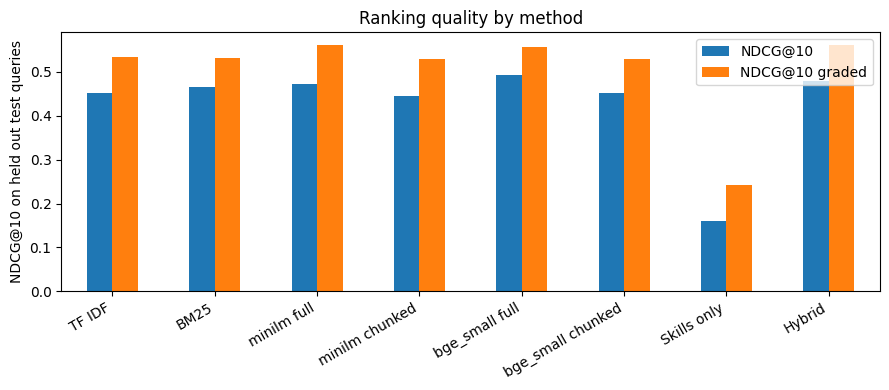

In [48]:
fig, ax = plt.subplots(figsize=(9, 4))
test_results[["NDCG@10", "NDCG@10 graded"]].plot(kind="bar", ax=ax)
ax.set_ylabel("NDCG@10 on held out test queries")
ax.set_xlabel("")
ax.set_title("Ranking quality by method")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "method_comparison.png", dpi=150)
plt.show()

### How sure are we?
With under 100 test queries, small gaps between methods can be luck. The intervals below come
from resampling job titles. If an interval for a DIFFERENCE includes zero, we cannot claim
that one method is really better than the other.

In [49]:
test_groups = queries.loc[test_mask, "group"].values

compare = {
    "TF IDF": tfidf_scores,
    "BM25": bm25_scores,
    f"Best embedding ({best_variant})": variant_scores[best_variant],
    "Hybrid": hybrid_n,
}
per_query = {
    name: per_query_metrics(matrix[test_mask], relevance_graded[test_mask])["NDCG@10"]
    for name, matrix in compare.items()
}

ci_rows = []
for name, values in per_query.items():
    low, high = bootstrap_ci(values, test_groups)
    ci_rows.append({"method": name, "NDCG@10 graded": values.mean(), "CI low": low, "CI high": high})
print(pd.DataFrame(ci_rows).round(3).to_string(index=False))

print()
for other in ["TF IDF", "BM25"]:
    difference = per_query["Hybrid"] - per_query[other]
    low, high = bootstrap_ci(difference, test_groups)
    print(f"Hybrid minus {other}: mean {difference.mean():.3f}, 95% CI [{low:.3f}, {high:.3f}]")

                      method  NDCG@10 graded  CI low  CI high
                      TF IDF           0.535   0.459    0.613
                        BM25           0.531   0.460    0.602
Best embedding (minilm full)           0.562   0.481    0.637
                      Hybrid           0.561   0.479    0.637

Hybrid minus TF IDF: mean 0.026, 95% CI [-0.015, 0.068]
Hybrid minus BM25: mean 0.031, 95% CI [-0.019, 0.079]


## 13. Diagnosis by category
These numbers use ALL queries (tuning and test), so every category has more queries.
They are for understanding failures only. Never report them as the final result.
Categories with very few queries are noisy.

In [50]:
diag_methods = {
    "TF IDF": tfidf_scores,
    "BM25": bm25_scores,
    "Best embedding": variant_scores[best_variant],
    "Hybrid": hybrid_n,
}
all_mask = np.ones(len(queries), dtype=bool)

rows = []
for category in sorted(queries["category"].unique()):
    mask = (queries["category"] == category).values
    row = {"category": category, "queries": int(mask.sum())}
    for name, matrix in diag_methods.items():
        row[name] = per_query_metrics(matrix[mask], relevance_strict[mask])["NDCG@10"].mean()
    rows.append(row)

pd.DataFrame(rows).set_index("category").round(3).sort_values("Hybrid")

,queries,TF IDF,BM25,Best embedding,Hybrid
category,,,,,
ENGINEERING,20,0.348,0.362,0.296,0.309
HEALTHCARE,22,0.305,0.389,0.296,0.319
SALES,15,0.147,0.133,0.433,0.351
TEACHER,6,0.412,0.516,0.395,0.383
INFORMATION-TECHNOLOGY,19,0.409,0.413,0.399,0.406
FINANCE,9,0.270,0.274,0.419,0.408
BUSINESS-DEVELOPMENT,4,0.526,0.271,0.482,0.466
ACCOUNTANT,9,0.544,0.431,0.594,0.601
DIGITAL-MEDIA,15,0.813,0.756,0.635,0.693


In [51]:
# Which categories does the best embedding return in the top 10, for each job category?
for category in sorted(queries["category"].unique()):
    mask = (queries["category"] == category).values
    found = []
    for scores in variant_scores[best_variant][mask]:
        found.extend(resumes["Category"].iloc[np.argsort(-scores)[:10]].tolist())
    top3 = pd.Series(found).value_counts(normalize=True).head(3)
    print(category, {name: round(float(share), 2) for name, share in top3.items()})

ACCOUNTANT {'ACCOUNTANT': 0.59, 'FINANCE': 0.24, 'BANKING': 0.06}
BUSINESS-DEVELOPMENT {'BUSINESS-DEVELOPMENT': 0.47, 'DIGITAL-MEDIA': 0.15, 'SALES': 0.12}
DESIGNER {'DESIGNER': 0.76, 'APPAREL': 0.07, 'INFORMATION-TECHNOLOGY': 0.04}
DIGITAL-MEDIA {'DIGITAL-MEDIA': 0.6, 'PUBLIC-RELATIONS': 0.19, 'APPAREL': 0.07}
ENGINEERING {'ENGINEERING': 0.3, 'AVIATION': 0.2, 'DESIGNER': 0.15}
FINANCE {'FINANCE': 0.46, 'BANKING': 0.23, 'CONSULTANT': 0.09}
HEALTHCARE {'HEALTHCARE': 0.27, 'ADVOCATE': 0.2, 'FITNESS': 0.15}
HR {'HR': 0.8, 'HEALTHCARE': 0.07, 'ADVOCATE': 0.03}
INFORMATION-TECHNOLOGY {'INFORMATION-TECHNOLOGY': 0.4, 'CONSULTANT': 0.11, 'ENGINEERING': 0.08}
PUBLIC-RELATIONS {'PUBLIC-RELATIONS': 0.93, 'APPAREL': 0.07}
SALES {'SALES': 0.39, 'BUSINESS-DEVELOPMENT': 0.31, 'PUBLIC-RELATIONS': 0.05}
TEACHER {'TEACHER': 0.42, 'ARTS': 0.38, 'DESIGNER': 0.12}


## 14. The screening function with explanations
This is the heart of the future app. Give it a job description and it returns a ranked table
with matched and missing skills and a plain language summary for each candidate.
The 0 to 100 fit score is relative to this resume pool, it is not an absolute rating.

In [52]:
COMPONENT_LABELS = {"bm25": "keyword match", "embedding": "meaning match", "skills": "skill coverage"}


def embedding_part(jd_clean):
    """Score every resume with the winning embedding variant."""
    store = variant_store[best_variant]
    query_vec = encode_queries(store["model_key"], [jd_clean])
    sims = query_vec @ store["doc_emb"].T
    if store["starts"] is not None:
        sims = chunk_scores_to_resume_scores(sims, store["starts"])
    return sims[0]


def screen(jd_text, top_n=5, weights=BEST_WEIGHTS):
    jd_clean = clean_text(jd_text)
    jd_weights = jd_skill_weights(jd_text)

    coverage = np.array([skill_coverage(s, jd_weights) for s in resume_skill_sets])
    parts = {
        "bm25": normalise_rows(bm25.score(jd_clean)[None, :])[0],
        "embedding": normalise_rows(embedding_part(jd_clean)[None, :])[0],
        "skills": normalise_rows(coverage[None, :])[0],
    }
    final = sum(weights[name] * parts[name] for name in parts)

    required = {s for s, w in jd_weights.items() if w == REQUIRED_WEIGHT}
    preferred = {s for s, w in jd_weights.items() if w == PREFERRED_WEIGHT}

    rows = []
    for rank, idx in enumerate(np.argsort(-final)[:top_n], start=1):
        have = resume_skill_sets[idx]
        rows.append({
            "rank": rank,
            "resume_id": resumes["ID"].iloc[idx],
            "category": resumes["Category"].iloc[idx],
            "score": round(final[idx] * 100, 1),
            "skill_match_pct": round(coverage[idx] * 100),
            "matched": sorted(have & set(jd_weights)),
            "missing_required": sorted(required - have),
            "missing_preferred": sorted(preferred - have),
            **{f"{name}_part": weights[name] * parts[name][idx] for name in parts},
        })
    return pd.DataFrame(rows), jd_weights


def explain(row, weights=BEST_WEIGHTS):
    """Write a short plain language summary for one ranked candidate."""
    contributions = {name: row[f"{name}_part"] for name in weights}
    strongest = COMPONENT_LABELS[max(contributions, key=contributions.get)]
    text = f"Ranked {row['rank']} with a fit score of {row['score']}. Strongest signal: {strongest}. "
    text += f"Skill match: {row['skill_match_pct']} percent. "
    text += "Matches: " + (", ".join(row["matched"]) if row["matched"] else "no listed skills") + ". "
    if row["missing_required"]:
        text += "Missing required skills: " + ", ".join(row["missing_required"]) + ". "
    if row["missing_preferred"]:
        text += "Missing preferred skills: " + ", ".join(row["missing_preferred"]) + "."
    return text.strip()

In [53]:
# A job description you can edit freely. Try your own roles here.
MY_JOB = """
We are hiring a Data Analyst. Required: strong SQL and Python skills, experience building
dashboards in Power BI, and solid knowledge of statistics. You will clean data, build reports
and present insights to stakeholders. Preferred: machine learning, cloud experience on AWS,
and familiarity with Git. Nice to have: Excel automation.
"""

ranking, job_skill_weights = screen(MY_JOB, top_n=5)
print("Skills found in the job:", job_skill_weights)
print()
for _, row in ranking.iterrows():
    print(explain(row))
    print()

Skills found in the job: {'python': 1.0, 'data visualization': 1.0, 'power bi': 1.0, 'statistics': 1.0, 'sql': 1.0, 'machine learning': 0.5, 'git': 0.5, 'aws': 0.5, 'excel': 0.5}

Ranked 1 with a fit score of 96.8. Strongest signal: meaning match. Skill match: 79 percent. Matches: data visualization, excel, power bi, python, sql, statistics. Missing preferred skills: aws, git, machine learning.

Ranked 2 with a fit score of 93.6. Strongest signal: meaning match. Skill match: 64 percent. Matches: data visualization, machine learning, python, sql, statistics. Missing required skills: power bi. Missing preferred skills: aws, excel, git.

Ranked 3 with a fit score of 91.8. Strongest signal: meaning match. Skill match: 50 percent. Matches: data visualization, machine learning, python, sql. Missing required skills: power bi, statistics. Missing preferred skills: aws, excel, git.

Ranked 4 with a fit score of 86.3. Strongest signal: meaning match. Skill match: 36 percent. Matches: aws, python

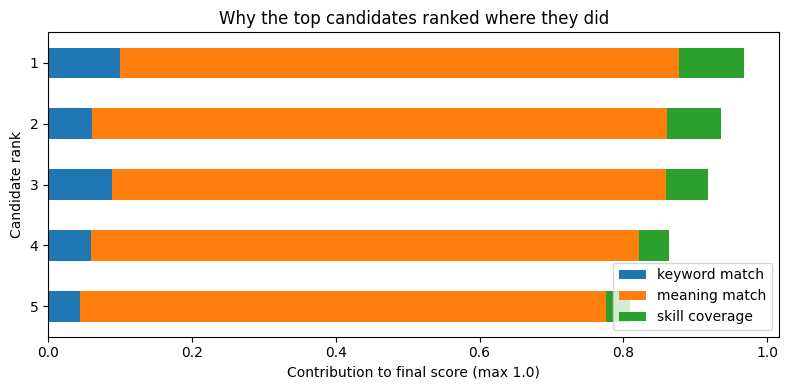

In [54]:
# Visual comparison: how much each scorer contributed to each top candidate.
part_columns = [f"{name}_part" for name in BEST_WEIGHTS]
plot_data = ranking.set_index("rank")[part_columns]
plot_data.columns = [COMPONENT_LABELS[name] for name in BEST_WEIGHTS]

ax = plot_data.iloc[::-1].plot(kind="barh", stacked=True, figsize=(8, 4))
ax.set_xlabel("Contribution to final score (max 1.0)")
ax.set_ylabel("Candidate rank")
ax.set_title("Why the top candidates ranked where they did")
plt.tight_layout()
plt.savefig(FIG_DIR / "top_candidates.png", dpi=150)
plt.show()

In [55]:
# Demo on roles outside data science, to show the system is not tied to one field.
DEMO_JOBS = {
    "HR Officer": """
    We are hiring an HR Officer. Required: recruitment experience, onboarding of new staff,
    employee relations, and knowledge of payroll and HRIS systems. Preferred: performance
    management and training and development.
    """,
    "Accountant": """
    We are hiring an Accountant. Required: accounts payable, accounts receivable, reconciliation
    and financial reporting, with hands on QuickBooks experience. Preferred: tax, auditing and SAP.
    """,
    "Graphic Designer": """
    We are hiring a Graphic Designer. Required: Photoshop, Illustrator and Figma, with strong
    graphic design and UI design skills. Preferred: UX design, HTML and CSS.
    """,
}

for job_title, job_text in DEMO_JOBS.items():
    demo_ranking, demo_skills = screen(job_text, top_n=3)
    print("=" * 70)
    print(job_title, "| skills found:", demo_skills)
    for _, row in demo_ranking.iterrows():
        print(f"[{row['category']}]", explain(row))
        print()

HR Officer | skills found: {'recruitment': 1.0, 'onboarding': 1.0, 'employee relations': 1.0, 'hris': 1.0, 'payroll': 1.0, 'training and development': 1.0}
[HR] Ranked 1 with a fit score of 97.3. Strongest signal: meaning match. Skill match: 83 percent. Matches: employee relations, hris, onboarding, payroll, recruitment. Missing required skills: training and development.

[HR] Ranked 2 with a fit score of 93.5. Strongest signal: meaning match. Skill match: 83 percent. Matches: employee relations, hris, payroll, recruitment, training and development. Missing required skills: onboarding.

[HR] Ranked 3 with a fit score of 93.4. Strongest signal: meaning match. Skill match: 50 percent. Matches: onboarding, recruitment, training and development. Missing required skills: employee relations, hris, payroll.

Accountant | skills found: {'accounts payable': 1.0, 'accounts receivable': 1.0, 'reconciliation': 1.0, 'quickbooks': 1.0, 'financial reporting': 1.0, 'tax': 0.5, 'auditing': 0.5, 'sap': 

## 15. Save the results
These files feed the README and the later FastAPI service.

In [56]:
def to_markdown_table(df):
    """Turn a dataframe into a markdown table, with no extra library needed."""
    header = "| " + " | ".join(df.columns) + " |"
    divider = "| " + " | ".join("---" for _ in df.columns) + " |"
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([header, divider] + body)


metrics_table = test_results.reset_index().rename(columns={"method": "Method"})
ci_table = pd.DataFrame(ci_rows).round(3)

diff_lines = []
for other in ["TF IDF", "BM25"]:
    difference = per_query["Hybrid"] - per_query[other]
    low, high = bootstrap_ci(difference, test_groups)
    diff_lines.append(f"* Hybrid minus {other}: {difference.mean():.3f} (95% CI {low:.3f} to {high:.3f})")

readme_text = "\n".join([
    "### Held out test results",
    "",
    to_markdown_table(metrics_table),
    "",
    "### Graded NDCG@10 with 95% bootstrap confidence intervals",
    "",
    to_markdown_table(ci_table),
    "",
    "\n".join(diff_lines),
    "",
    f"Best embedding variant (chosen on tuning queries): {best_variant}",
    f"Hybrid weights: {BEST_WEIGHTS}",
])

(OUTPUT_DIR / "readme_results.md").write_text(readme_text)
print(readme_text)

### Held out test results

| Method | P@10 | MRR | NDCG@10 | NDCG@10 graded |
| --- | --- | --- | --- | --- |
| TF IDF | 0.457 | 0.575 | 0.452 | 0.535 |
| BM25 | 0.466 | 0.609 | 0.465 | 0.531 |
| minilm full | 0.476 | 0.617 | 0.473 | 0.562 |
| minilm chunked | 0.454 | 0.584 | 0.445 | 0.53 |
| bge_small full | 0.503 | 0.627 | 0.494 | 0.557 |
| bge_small chunked | 0.451 | 0.627 | 0.451 | 0.529 |
| Skills only | 0.182 | 0.173 | 0.16 | 0.243 |
| Hybrid | 0.486 | 0.596 | 0.48 | 0.561 |

### Graded NDCG@10 with 95% bootstrap confidence intervals

| method | NDCG@10 graded | CI low | CI high |
| --- | --- | --- | --- |
| TF IDF | 0.535 | 0.459 | 0.613 |
| BM25 | 0.531 | 0.46 | 0.602 |
| Best embedding (minilm full) | 0.562 | 0.481 | 0.637 |
| Hybrid | 0.561 | 0.479 | 0.637 |

* Hybrid minus TF IDF: 0.026 (95% CI -0.015 to 0.068)
* Hybrid minus BM25: 0.031 (95% CI -0.019 to 0.079)

Best embedding variant (chosen on tuning queries): minilm full
Hybrid weights: {'bm25': 0.1, 'embedding': 0.8, 's

In [57]:
test_results.to_csv(OUTPUT_DIR / "metrics.csv")

config = {
    "best_variant": best_variant,
    "embedding_model": EMBED_MODELS[variant_store[best_variant]["model_key"]],
    "chunked": variant_store[best_variant]["starts"] is not None,
    "chunk_words": CHUNK_WORDS,
    "weights": BEST_WEIGHTS,
    "min_skill_weight": MIN_SKILL_WEIGHT,
    "required_weight": REQUIRED_WEIGHT,
    "preferred_weight": PREFERRED_WEIGHT,
    "excluded_categories": sorted(EXCLUDED_CATEGORIES),
    "related_groups": [sorted(group) for group in RELATED_GROUPS],
}
with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)
with open(OUTPUT_DIR / "skill_aliases.json", "w") as f:
    json.dump(SKILL_ALIASES, f, indent=2)

print("Saved to", OUTPUT_DIR)

Saved to /kaggle/working/outputs


## Findings and limitations

**What we found**
* Sentence embeddings gave small gains over TF IDF and BM25, but the gains are not statistically significant on the held out queries.
* The hybrid performs on par with the best single method. Its value is that skills influence the score and every ranking comes with matched and missing skills in plain language.
* Splitting resumes into chunks and scoring the best chunk did not help. The whole resume version did better for both embedding models.
* Graded relevance scores are higher than strict ones, which shows many "misses" are sensible neighbour categories.

**Limitations**
* Resume categories are a proxy for hiring decisions, not real hiring outcomes.
* The ADVOCATE category was excluded from evaluation because most of its resumes did not look legal. We noticed this through poor scores and then checked it, and the check itself was crude.
* The job descriptions are synthetic and templated, so real postings may behave differently.
* The related category groups used for graded relevance are a judgement call, so strict results are reported too.
* There are fewer than 100 test queries, so confidence intervals are wide and per category numbers are noisy.
* The skill dictionary is hand written and covers some fields better than others.
* The fit score is relative to the resume pool and is not an absolute rating of a candidate.

In [58]:
# CELL A: build and save the bundle the app will load.
from scipy import sparse

# The app embeds whole resumes only, so the winning variant must be a "full" one.
assert variant_store[best_variant]["starts"] is None, "The app bundle needs a whole resume variant."

embed_model_key = variant_store[best_variant]["model_key"]
embed_model_id = EMBED_MODELS[embed_model_key]
if "/" not in embed_model_id:
    embed_model_id = "sentence-transformers/" + embed_model_id  # the full Hub repo id

# The exact commit of the public embedding model, so the app can pin it.
try:
    from huggingface_hub import HfApi
    embed_model_revision = HfApi().model_info(embed_model_id).sha
except Exception as error:
    embed_model_revision = None
    print("Could not read the model revision, add it by hand:", error)
print("Embedding model:", embed_model_id, "revision:", embed_model_revision)

# BM25 needs the word counts of the reference resumes. We save them as a sparse matrix
# in three plain arrays, so no pickle is involved and library versions cannot break loading.
tf = bm25.counts.tocsr()
vocabulary = sorted(bm25.vectorizer.vocabulary_, key=bm25.vectorizer.vocabulary_.get)

app_config = {
    "embedding_model_id": embed_model_id,
    "embedding_model_revision": embed_model_revision,
    "embedding_max_seq_length": 384,
    "weights": BEST_WEIGHTS,
    "min_skill_weight": MIN_SKILL_WEIGHT,
    "required_weight": REQUIRED_WEIGHT,
    "preferred_weight": PREFERRED_WEIGHT,
    "preferred_cues": PREFERRED_CUES,
    "bm25_k1": bm25.k1,
    "bm25_b": bm25.b,
    "reference_resumes": int(len(resumes)),
    "best_variant": best_variant,
}

BUNDLE_FILE = OUTPUT_DIR / "screening_bundle.npz"
np.savez_compressed(
    BUNDLE_FILE,
    tf_data=tf.data.astype(np.int32),
    tf_indices=tf.indices.astype(np.int32),
    tf_indptr=tf.indptr.astype(np.int64),
    tf_shape=np.array(tf.shape),
    vocabulary=np.array(vocabulary, dtype=str),  # dtype=str keeps it a plain array, so no pickle is needed
    idf=bm25.idf.astype(np.float64),
    doc_len=bm25.doc_len.astype(np.float64),
    ref_embeddings=variant_store[best_variant]["doc_emb"].astype(np.float32),
    ref_ids=resumes["ID"].values.astype(np.int64),
    ref_categories=np.array(resumes["Category"].tolist(), dtype=str),
    ref_skill_sets_json=np.array(json.dumps([sorted(s) for s in resume_skill_sets])),
    skill_aliases_json=np.array(json.dumps(SKILL_ALIASES)),
    config_json=np.array(json.dumps(app_config)),
)
print("Saved", BUNDLE_FILE, round(BUNDLE_FILE.stat().st_size / 1e6, 1), "MB")

Embedding model: sentence-transformers/all-MiniLM-L6-v2 revision: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
Saved /kaggle/working/outputs/screening_bundle.npz 5.5 MB


In [59]:
# CELL B: the scoring functions the app will use. They read ONLY from the bundle.
def load_bundle(path):
    raw = np.load(path, allow_pickle=False)
    aliases = json.loads(str(raw["skill_aliases_json"]))

    skill_nlp = spacy.blank("en")
    skill_matcher = PhraseMatcher(skill_nlp.vocab, attr="LOWER")
    for canonical, alias_list in aliases.items():
        patterns = [skill_nlp.make_doc(clean_text(name)) for name in [canonical] + alias_list]
        skill_matcher.add(canonical, patterns)

    vocab = {term: i for i, term in enumerate(raw["vocabulary"].tolist())}
    ref_tf = sparse.csr_matrix(
        (raw["tf_data"], raw["tf_indices"], raw["tf_indptr"]),
        shape=tuple(int(x) for x in raw["tf_shape"]),
    ).tocsc()
    return {
        "config": json.loads(str(raw["config_json"])),
        "nlp": skill_nlp,
        "matcher": skill_matcher,
        # Same settings as training, with the saved vocabulary instead of a fit.
        "vectorizer": CountVectorizer(stop_words="english", vocabulary=vocab),
        "ref_tf": ref_tf,
        "idf": raw["idf"],
        "doc_len": raw["doc_len"],
        "ref_emb": raw["ref_embeddings"],
        "ref_ids": raw["ref_ids"],
        "ref_categories": raw["ref_categories"],
        "ref_skill_sets": [set(s) for s in json.loads(str(raw["ref_skill_sets_json"]))],
    }


def bundle_extract_skills(bundle, text):
    doc = bundle["nlp"].make_doc(clean_text(text))
    return {bundle["nlp"].vocab.strings[match_id] for match_id, start, end in bundle["matcher"](doc)}


def bundle_jd_weights(bundle, jd_text):
    config = bundle["config"]
    weights = {}
    for sentence in re.split(r"(?<=[.!?\n])\s+", str(jd_text)):
        is_preferred = any(cue in sentence.lower() for cue in config["preferred_cues"])
        weight = config["preferred_weight"] if is_preferred else config["required_weight"]
        for skill in bundle_extract_skills(bundle, sentence):
            weights[skill] = max(weights.get(skill, 0.0), weight)
    return weights


def bm25_from_counts(counts_csc, doc_len, query_terms, idf, avg_len, k1, b):
    """The same BM25 formula as SimpleBM25.score, for any matrix of word counts."""
    scores = np.zeros(counts_csc.shape[0])
    length_norm = k1 * (1 - b + b * doc_len / avg_len)
    for term in query_terms:
        tf_column = counts_csc[:, term].toarray().ravel()
        scores += idf[term] * (tf_column * (k1 + 1)) / (tf_column + length_norm)
    return scores


def score_uploaded(bundle, jd_text, resume_texts, embed_fn, return_reference=False):
    """Score uploaded resumes against a job description.
    The uploaded resumes are scaled against the reference pool (min and max over both),
    so a score means 'how this resume compares with thousands of others', not just
    'how it compares with the few resumes in this request'.
    embed_fn takes a list of cleaned texts and returns normalised vectors."""
    config = bundle["config"]
    weights = config["weights"]
    n_ref = len(bundle["ref_skill_sets"])

    # Same preprocessing as the reference pool, so scores stay on the same scale.
    bodies = [strip_leading_title(text) for text in resume_texts]
    cleaned = [clean_text(body) for body in bodies]
    jd_clean = clean_text(jd_text)

    # Meaning match.
    vectors = embed_fn([jd_clean] + cleaned)
    query_vec, upload_emb = vectors[0], vectors[1:]
    ref_embed = bundle["ref_emb"] @ query_vec
    embed_raw = np.concatenate([ref_embed, upload_emb @ query_vec])

    # Keyword match. IDF and average length come from the reference pool only.
    vectorizer = bundle["vectorizer"]
    query_terms = np.unique(vectorizer.transform([jd_clean]).indices)
    avg_len = bundle["doc_len"].mean()
    k1, b = config["bm25_k1"], config["bm25_b"]
    ref_bm25 = bm25_from_counts(bundle["ref_tf"], bundle["doc_len"], query_terms, bundle["idf"], avg_len, k1, b)
    upload_counts = vectorizer.transform(cleaned).tocsc()
    upload_len = np.asarray(upload_counts.sum(axis=1)).ravel()
    upload_bm25 = bm25_from_counts(upload_counts, upload_len, query_terms, bundle["idf"], avg_len, k1, b)
    bm25_raw = np.concatenate([ref_bm25, upload_bm25])

    # Skill coverage.
    jd_weights = bundle_jd_weights(bundle, jd_text)
    upload_skills = [bundle_extract_skills(bundle, body) for body in bodies]
    coverage = np.array([skill_coverage(s, jd_weights) for s in bundle["ref_skill_sets"] + upload_skills])

    parts = {
        "bm25": normalise_rows(bm25_raw[None, :])[0],
        "embedding": normalise_rows(embed_raw[None, :])[0],
        "skills": normalise_rows(coverage[None, :])[0],
    }
    final = sum(weights[name] * parts[name] for name in parts)

    required = {s for s, w in jd_weights.items() if w == config["required_weight"]}
    preferred = {s for s, w in jd_weights.items() if w == config["preferred_weight"]}

    results = []
    for i, have in enumerate(upload_skills):
        idx = n_ref + i
        results.append({
            "score": round(float(final[idx]) * 100, 1),
            "skill_match_pct": int(round(float(coverage[idx]) * 100)),
            "matched": sorted(have & set(jd_weights)),
            "missing_required": sorted(required - have),
            "missing_preferred": sorted(preferred - have),
            "parts": {name: round(float(weights[name] * parts[name][idx]), 4) for name in parts},
        })
    order = sorted(range(len(results)), key=lambda i: (-results[i]["score"], i))
    for rank, i in enumerate(order, start=1):
        results[i]["rank"] = rank

    output = {"results": results, "jd_skill_weights": jd_weights}
    if return_reference:
        output["reference"] = {"bm25": ref_bm25, "embedding": ref_embed, "skills": coverage[:n_ref]}
    return output

In [60]:
# CELL C: prove the saved bundle reproduces the notebook, then save a parity fixture.
bundle = load_bundle(BUNDLE_FILE)


def notebook_embed(texts):
    return encode_queries(embed_model_key, texts)


# Check 1: the reference scores rebuilt from the bundle equal the notebook's own scores.
check = score_uploaded(bundle, MY_JOB, resumes["resume_body"].iloc[:3].tolist(), notebook_embed, return_reference=True)
jd_clean = clean_text(MY_JOB)
jd_weights_nb = jd_skill_weights(MY_JOB)
assert np.allclose(check["reference"]["bm25"], bm25.score(jd_clean)), "BM25 mismatch"
assert np.allclose(check["reference"]["embedding"], embedding_part(jd_clean), atol=1e-4), "Embedding mismatch"
assert np.allclose(
    check["reference"]["skills"], [skill_coverage(s, jd_weights_nb) for s in resume_skill_sets]
), "Skill mismatch"
print("Bundle round trip OK")

Bundle round trip OK


In [61]:
# Four small made up resumes, so the fixture contains no real personal data.
FIXTURE_RESUMES = [
    {"name": "data_analyst", "text": (
        "JANE MWANGI Data Analyst Summary Data analyst with three years of experience. "
        "Built dashboards in Power BI, wrote SQL queries and used Python and pandas for statistics. "
        "Worked with Git and Excel. Cleaned data and presented insights to stakeholders.")},
    {"name": "hr_officer", "text": (
        "PETER OMONDI HR Officer Summary Human resources professional focused on recruitment, "
        "onboarding and employee relations. Managed payroll and training and development programmes.")},
    {"name": "accountant", "text": (
        "AMINA HASSAN Accountant Summary Accountant handling accounts payable, accounts receivable, "
        "reconciliation and financial reporting in QuickBooks. Supported tax filing and audit work.")},
    {"name": "software_developer", "text": (
        "DAVID KAMAU Software Developer Summary Developer with Python, SQL, Docker and AWS experience. "
        "Built REST APIs, used Git daily and worked in agile teams. Some machine learning projects.")},
]
fixture_texts = [item["text"] for item in FIXTURE_RESUMES]
fixture_cleaned = [clean_text(strip_leading_title(t)) for t in fixture_texts]

vectors = notebook_embed([clean_text(MY_JOB)] + fixture_cleaned)
fixture_output = score_uploaded(bundle, MY_JOB, fixture_texts, notebook_embed, return_reference=True)

parity_fixture = {
    "job_description": MY_JOB,
    "resumes": FIXTURE_RESUMES,
    "job_vector": [float(x) for x in vectors[0]],
    "resume_vectors": [[float(x) for x in v] for v in vectors[1:]],
    "expected_results": fixture_output["results"],
    "expected_jd_skill_weights": fixture_output["jd_skill_weights"],
    "reference_bm25_top5_ids": [int(i) for i in bundle["ref_ids"][np.argsort(-fixture_output["reference"]["bm25"])[:5]]],
    "reference_skill_coverage_sum": float(fixture_output["reference"]["skills"].sum()),
}
with open(OUTPUT_DIR / "parity_fixture.json", "w") as f:
    json.dump(parity_fixture, f, indent=2)

for item, result in zip(FIXTURE_RESUMES, fixture_output["results"]):
    print(item["name"], result["rank"], result["score"], result["skill_match_pct"])

data_analyst 1 100.0 86
hr_officer 3 26.5 0
accountant 4 21.7 0
software_developer 2 79.3 50
